# 06.4 · Model comparison: how many copies and how much income can a new Kindle book expect?

**Project:** Digital Publishing Opportunity Intelligence

**Author:** Stefan Radević · Data Science Bootcamp · Capstone project

## 1. TL;DR

**Answer: partly.**

- I chose **gradient boosting** by its validation score (R² **0.284**). It explains **29.5%** of the differences in copies between new test books.
- It predicts the **typical** sales of a niche well (Spearman **0.90** between real and predicted niche medians), but not single hits.
- With the 2026 Kindle rules, a self-published first Romance book at 4.99 dollars earns the author about **122 dollars a year**.
- **Sub-question:** for less-known authors without hits the model works as well as for others (R² 0.22). It puts **Cookbooks**, **Health** and **Sports** first, and Romance and
  Mystery pay a new author little.

## 2. Recap

**Main question.** How many copies a year can a new Kindle book expect, from its niche, price, length, series, publishing route and the
author's experience?

**Sub-question.** How well does the model work for **less-known authors without hits** (at most 2 earlier books, not in the top 1% of sales),
and which niches does it expect to pay them most?

Notebooks 06.1, 06.2 and 06.3 trained linear regression, a random forest and gradient boosting on the same training books, and tested them on
the same **11,015 test books** from authors they had not seen. The copies sold are **synthetic example data** (`03`), so the results show the
method, not real Amazon sales. This notebook compares the models, chooses one, turns its predicted copies into **income** with the Kindle rules
from `04`, and answers the sub-question.

## 3. Setup

I load the saved predictions, results and models of the three notebooks, and the book table from `04`. No model is trained here.

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, median_absolute_error, r2_score

PROJECT = Path("..") if Path.cwd().name == "notebooks" else Path(".")
PROCESSED = PROJECT / "data" / "processed"
MODELS_DIR = PROJECT / "models"
TARGET = "copies_per_year"
BLUE, ORANGE, GREY, GREEN = "#2a78d6", "#eb6834", "#c3c2b7", "#3a9a5b"
ROUTE_COLORS = {"self-published": BLUE, "small publisher": GREEN, "large publisher": ORANGE}
pd.set_option("display.max_columns", 30, "display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

MODELS = {"Linear regression": "linear_regression", "Random forest": "random_forest", "Gradient boosting": "gradient_boosting"}
predictions = {name: pd.read_parquet(PROCESSED / f"predictions_sales_{slug}.parquet").set_index("parent_asin") for name, slug in MODELS.items()}
summaries = {name: json.loads((PROCESSED / f"results_sales_{slug}.json").read_text(encoding="utf-8")) for name, slug in MODELS.items()}
books = pd.read_parquet(PROCESSED / "kindle_books_sales_income.parquet")
first = predictions["Linear regression"]
print("Test books:", len(first), "| all books:", len(books))
print("Same test books in all notebooks:", all(set(p.index) == set(first.index) for p in predictions.values()))

Test books: 11015 | all books: 55690
Same test books in all notebooks: True


- **11,015** test books are the same in all three notebooks, and the full table has **55,690** books for the sub-question.

## 4. Feature preparation

All models use the same six characteristics that an author knows before publishing: niche, price, pages, series, publishing route and the
author's earlier books. The target is `log(1 + copies per year)`. Linear regression uses the logarithms of price and earlier books; the tree
models use the original numbers.

## 5. Train/test split

The split is the same in all notebooks: **44,675 training books** and **11,015 test books**, with no author on both sides. The cell above
confirms that the three notebooks predicted the same test books.

## 6. Comparison

The table puts the **validation** results (5 folds on the training books, used to choose) next to the **test** results (used once). The
baseline always predicts the median of the training books.

In [2]:
def measures(true_log, predicted_log):
    true_copies, predicted_copies = np.expm1(true_log), np.expm1(predicted_log)
    return {"R2 (log)": r2_score(true_log, predicted_log), "MAE (log)": mean_absolute_error(true_log, predicted_log),
            "MAE (copies)": mean_absolute_error(true_copies, predicted_copies),
            "median error (copies)": median_absolute_error(true_copies, predicted_copies),
            "within 2x %": (np.abs(true_log - predicted_log) <= np.log(2)).mean() * 100}


true_log = first["log_copies"]
train_books = books[~books["parent_asin"].isin(first.index)]
baseline_log = pd.Series(np.log1p(train_books[TARGET]).median(), index=first.index)
print(f"Training books: {len(train_books):,}; the baseline predicts {np.expm1(baseline_log.iloc[0]):.0f} copies for every test book")
rows = [{"model": "Baseline (median)", "CV R2": np.nan, "CV std": np.nan, "train R2": np.nan, **measures(true_log, baseline_log)}]
for name, table in predictions.items():
    s = summaries[name]
    rows.append({"model": name, "CV R2": s["cv_r2"], "CV std": s["cv_std"], "train R2": s["train_r2"],
                 **measures(table["log_copies"], table["predicted_log"])})
comparison = pd.DataFrame(rows).set_index("model")
comparison.round(3)

Training books: 44,675; the baseline predicts 79 copies for every test book


,CV R2,CV std,train R2,R2 (log),MAE (log),MAE (copies),median error (copies),within 2x %
model,,,,,,,,
Baseline (median),NaN,NaN,NaN,-0.002,1.684,876.067,72.274,25.420
Linear regression,0.216,0.015,0.219,0.224,1.457,853.610,79.561,29.578
Random forest,0.270,0.012,0.346,0.284,1.387,834.756,78.185,31.784
Gradient boosting,0.284,0.012,0.324,0.295,1.378,832.981,75.217,31.403


- All three models beat the baseline on the log scale: R² **0.224** (linear regression), **0.284** (random forest) and **0.295** (gradient boosting), against −0.002.
- They are also more often within 2 times of the real copies: **29.6–31.8%** against 25.4%.
- The **typical error in copies** (75–80) is not smaller than the baseline's (72). For small books the errors in copies are small anyway; the models help mostly in relative
  terms and for groups.
- The random forest has the largest gap between training and validation (0.346 against 0.270).

**How to read the measures**

- **R² (log)** is the share of the differences between books that the model explains. The baseline says 79 copies for every book and explains nothing
  (R² = 0); a perfect model would hit every book exactly (R² = 1). It is measured on the log scale, so it compares **how many times** one book sells more
  than another: 10 against 100 copies counts the same as 1,000 against 10,000, and a few hits do not decide the result.
- **MAE (copies)** is the average miss in copies. It is large because of the hits: one book with 200,000 copies predicted at 220 raises the average for
  all books. So I also show the **median error (copies)**, the miss for a typical book.
- **MAE (log)** is the average miss in "how many times". `exp(MAE log)` turns it into a factor, shown below.
- **Within 2x %** is the share of books where the prediction is at most 2 times too high or too low. If the model says 50 copies, a book with 25 to 100
  copies counts as close.

In [3]:
factor = np.exp(comparison["MAE (log)"]).rename("typical miss (times)")
factor.round(1).to_frame()

,typical miss (times)
model,
Baseline (median),5.4
Linear regression,4.3
Random forest,4.0
Gradient boosting,4.0


- The baseline misses a typical book by about **5.4 times** and gradient boosting by about **4.0 times**: if it says 40 copies, the book often sells 10 or 160.
- So in plain words: gradient boosting explains about **30%** of the differences (R² 0.295), is close (within 2 times) for about **one book in three** (31.4%), and
  still misses a typical book by about 4 times.

The chart shows the validation and test R² of each model.

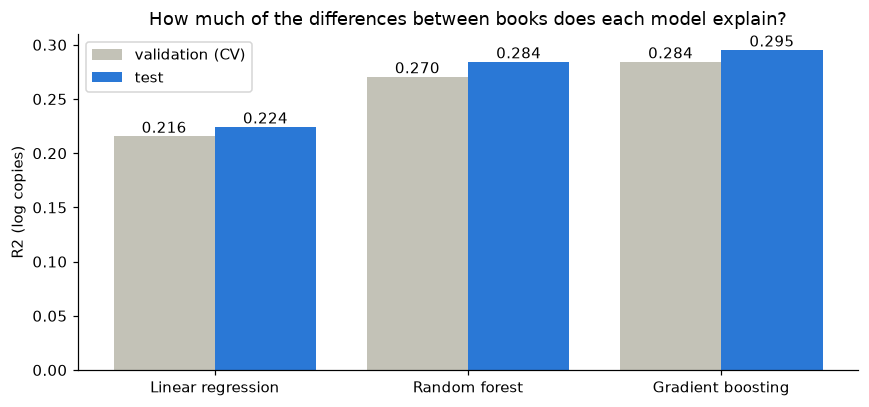

In [4]:
plot_table = comparison.drop(index="Baseline (median)")
positions = np.arange(len(plot_table))
fig, ax = plt.subplots(figsize=(8, 3.8))
bars1 = ax.bar(positions - 0.2, plot_table["CV R2"], 0.4, color=GREY, label="validation (CV)")
bars2 = ax.bar(positions + 0.2, plot_table["R2 (log)"], 0.4, color=BLUE, label="test")
ax.bar_label(bars1, fmt="%.3f")
ax.bar_label(bars2, fmt="%.3f")
ax.set_xticks(positions, plot_table.index)
ax.set_ylabel("R2 (log copies)")
ax.set_title("How much of the differences between books does each model explain?")
ax.legend()
plt.tight_layout()
plt.show()

- The tree models are clearly better than linear regression (about 0.27–0.30 against 0.22), so the curved effects of price, pages and experience matter.
- Validation and test agree for every model, so the test confirms the choice.

## 7. Choice of the final model

**Rule.** I choose the model with the **highest validation R²**, because the test books must not be used for choosing. If two models were
within one standard deviation, I would take the simpler one.

In [5]:
chosen = comparison["CV R2"].idxmax()
second = comparison["CV R2"].drop(chosen).idxmax()
gap = comparison.loc[chosen, "CV R2"] - comparison.loc[second, "CV R2"]
print(f"Chosen: {chosen} (CV R2 {comparison.loc[chosen, 'CV R2']:.4f} ± {comparison.loc[chosen, 'CV std']:.4f})")
print(f"Second: {second} (CV R2 {comparison.loc[second, 'CV R2']:.4f}); gap {gap:.4f}, one standard deviation {comparison.loc[chosen, 'CV std']:.4f}")
print("Settings:", summaries[chosen]["best_params"])
model = joblib.load(MODELS_DIR / f"sales_{MODELS[chosen]}.joblib")
final = predictions[chosen].copy()

Chosen: Gradient boosting (CV R2 0.2842 ± 0.0124)
Second: Random forest (CV R2 0.2704); gap 0.0138, one standard deviation 0.0124
Settings: {'learning_rate': 0.05, 'max_iter': 150, 'max_leaf_nodes': 31}


- **Gradient boosting** has the highest validation R² (**0.2842**). The random forest is second (0.2704); the gap (**0.0138**) is a little larger than one standard deviation
  (0.0124), and gradient boosting also overfits less. So I keep gradient boosting.

## 8. The final model on the test books

Does the model get the **typical** sales of each niche right? For every niche I compare the real median copies of the test books with the
predicted median. Points near the dashed line are niches where the model is right on average.

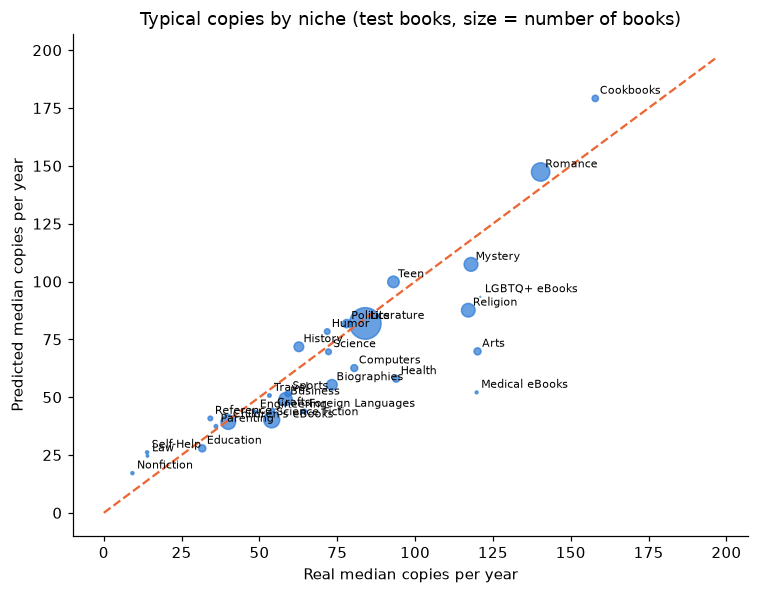

Spearman correlation of niche medians: 0.90


,books,real_median,predicted_median
niche,,,
"Cookbooks, Food & Wine",137,158.0,179.0
Romance,1155,140.0,147.0
LGBTQ+ eBooks,2,121.0,93.0
Arts & Photography,168,120.0,70.0
Medical eBooks,27,120.0,52.0
"Mystery, Thriller & Suspense",646,118.0,107.0
Religion & Spirituality,631,117.0,88.0
"Health, Fitness & Dieting",162,94.0,58.0
Teen & Young Adult,454,93.0,100.0


In [6]:
by_niche = final.groupby("niche").agg(books=(TARGET, "size"), real_median=(TARGET, "median"), predicted_median=("predicted_copies", "median"))
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(by_niche["real_median"], by_niche["predicted_median"], s=by_niche["books"] / 8, color=BLUE, alpha=0.7)
for niche, row in by_niche.iterrows():
    ax.annotate(niche.split(",")[0].split(" &")[0], (row["real_median"], row["predicted_median"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
limit = by_niche[["real_median", "predicted_median"]].max().max() * 1.1
ax.plot([0, limit], [0, limit], color=ORANGE, linestyle="--")
ax.set_xlabel("Real median copies per year")
ax.set_ylabel("Predicted median copies per year")
ax.set_title("Typical copies by niche (test books, size = number of books)")
plt.tight_layout()
plt.show()
print(f"Spearman correlation of niche medians: {by_niche['real_median'].corr(by_niche['predicted_median'], method='spearman'):.2f}")
by_niche.sort_values("real_median", ascending=False).round(0)

- The niches lie close to the dashed line: the Spearman correlation of real and predicted niche medians is **0.90**.
- **Cookbooks** (real 158, predicted 179) and **Romance** (140 vs 147) are on top, **Education & Teaching** (32 vs 28) near the bottom.
- The model is too low for some small niches, for example Arts & Photography (120 vs 70) and Medical eBooks (120 vs 52, only 27 books).

## 9. From copies to income

The model predicts copies. The author's income is **copies × dollars per copy**, and the dollars per copy follow the Kindle rules of 2026 from
`04` (section 9.3). First I check this on the test books: predicted income uses predicted copies and the book's own dollars per copy.

In [7]:
final["predicted_income"] = final["predicted_copies"] * final["author_per_copy"]
income_by_route = final.groupby("route").agg(books=(TARGET, "size"), real_median_income=("author_income", "median"),
                                             predicted_median_income=("predicted_income", "median"),
                                             real_mean_income=("author_income", "mean"), predicted_mean_income=("predicted_income", "mean"))
income_by_route.loc[["self-published", "small publisher", "large publisher"]].round(0)

,books,real_median_income,predicted_median_income,real_mean_income,predicted_mean_income
route,,,,,
self-published,5329,97.0,112.0,1020.0,218.0
small publisher,4148,139.0,165.0,1636.0,275.0
large publisher,1538,422.0,414.0,4178.0,847.0


- **Medians:** predicted and real income are close: self-published **112 vs 97** dollars a year, small publisher **165 vs 139**, large publisher **414 vs 422**.
- **Means:** the predicted means are much lower (**218** against 1,020 for self-published), because the model does not predict hits, and hits make most of the money.
- So the model gives a reasonable **typical** income, but not the chance of a big success.

Now the main use: **one invented draft**, a 250-page Romance novel, the author's first book, not in a series. For each route and price, the model
predicts the copies and the rules give the author's dollars per copy. The functions are the same as in `04`. For the delivery cost I use a file of
**2.5 MB**, close to the median of the books (2.47 MB).

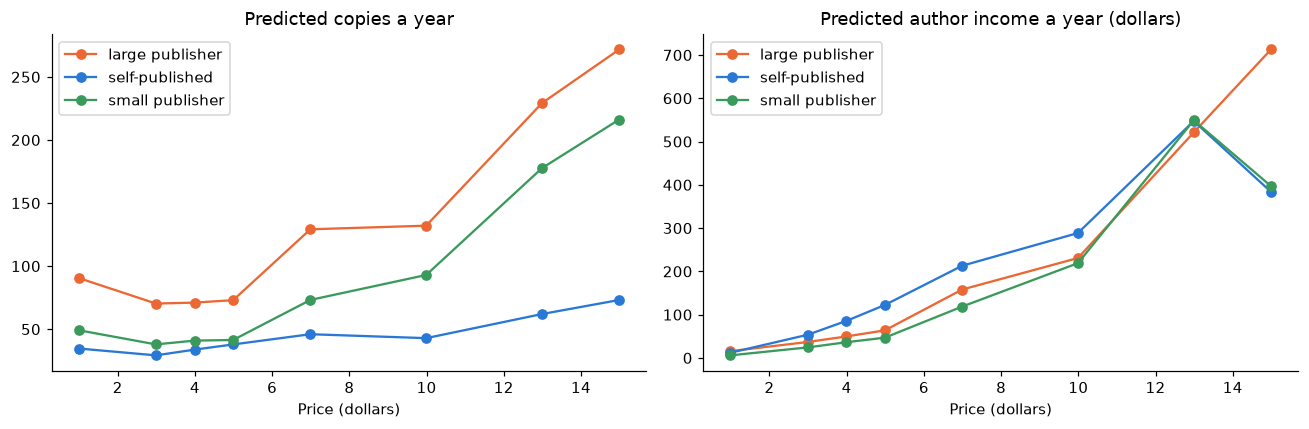

route,self-published,small publisher,large publisher
price,,,
0.99,12.0,6.0,16.0
2.99,54.0,24.0,37.0
3.99,85.0,36.0,50.0
4.99,122.0,47.0,64.0
6.99,213.0,119.0,158.0
9.99,289.0,219.0,231.0
12.99,547.0,549.0,521.0
14.99,384.0,397.0,713.0


In [8]:
KDP_70_BAND = (2.99, 12.99)
DELIVERY_PER_MB = 0.15
AGENCY_SHARE, LARGE_ROYALTY, SMALL_ROYALTY = 0.70, 0.25, 0.35
DRAFT_FILE_MB = 2.5


def kdp_royalty(price, file_mb):
    price = np.asarray(price, dtype=float)
    in_band = (price >= KDP_70_BAND[0]) & (price <= KDP_70_BAND[1])
    return np.where(in_band, np.maximum(0.35 * price, 0.70 * (price - DELIVERY_PER_MB * file_mb)), 0.35 * price)


def author_per_copy(price, route, file_mb=DRAFT_FILE_MB):
    if route == "self-published":
        return kdp_royalty(price, file_mb)
    if route == "small publisher":
        return SMALL_ROYALTY * kdp_royalty(price, file_mb)
    return LARGE_ROYALTY * AGENCY_SHARE * np.asarray(price, dtype=float)


def plan_income(draft, prices, routes=("self-published", "small publisher", "large publisher")):
    rows = []
    for route in routes:
        for price in prices:
            book = pd.DataFrame([{**draft, "route": route, "price": price}])
            if "log_price" in str(model):
                book["log_price"], book["log_earlier_books"] = np.log(price), np.log1p(book["author_earlier_books"])
            copies = float(np.expm1(model.predict(book)[0]))
            per_copy = float(author_per_copy(price, route))
            rows.append({"route": route, "price": price, "copies a year": copies, "dollars per copy": per_copy, "income a year": copies * per_copy})
    return pd.DataFrame(rows)


PRICES = [0.99, 2.99, 3.99, 4.99, 6.99, 9.99, 12.99, 14.99]
draft = {"niche": "Romance", "pages": 250, "is_series": 0, "author_earlier_books": 0}
plan = plan_income(draft, PRICES)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for route, part in plan.groupby("route"):
    axes[0].plot(part["price"], part["copies a year"], marker="o", color=ROUTE_COLORS[route], label=route)
    axes[1].plot(part["price"], part["income a year"], marker="o", color=ROUTE_COLORS[route], label=route)
axes[0].set_title("Predicted copies a year")
axes[1].set_title("Predicted author income a year (dollars)")
for ax in axes:
    ax.set_xlabel("Price (dollars)")
    ax.legend()
plt.tight_layout()
plt.show()
plan.pivot(index="price", columns="route", values="income a year")[["self-published", "small publisher", "large publisher"]].round(0)

- At **4.99 dollars** the first Romance book gives about **122 dollars a year** self-published, **47** with a small and **64** with a large publisher.
- **Self-published** gives the most income from 2.99 to 9.99 dollars, because the author keeps 61–68% of the price. At **12.99** all routes are close (**521–549 dollars**).
- Above 12.99 a self-published book falls to the 35% royalty (**384 dollars** at 14.99), while a large publisher keeps paying 17.5% (**713**).
- **Important:** the rise of copies with price is an association in this data (expensive books are often publisher books), not proof that a higher price sells more. The
  reliable part of this chart is the **rule**: how much of each price the author keeps on each route.

The same draft as a **series book by an author with 10 earlier books** shows how experience changes the picture. I show the best price for each route
for both authors.

In [9]:
experienced = plan_income({**draft, "is_series": 1, "author_earlier_books": 10}, PRICES)
best = pd.concat([plan.assign(author="first book"), experienced.assign(author="10 earlier, series")], ignore_index=True)
best = best.loc[best.groupby(["author", "route"])["income a year"].idxmax()].set_index(["author", "route"])
best.round(2)

price  copies a year  dollars per copy  income a year
author             route                                                                 
10 earlier, series large publisher  14.99         496.04              2.62        1301.23
                   self-published   12.99         223.79              8.83        1976.18
                   small publisher  12.99         331.68              3.09        1025.13
first book         large publisher  14.99         271.75              2.62         712.86
                   self-published   12.99          62.00              8.83         547.47
                   small publisher  12.99         177.69              3.09         549.17

- For a **first book** the highest predicted incomes are about **547–549 dollars** at 12.99 (self-published or small publisher) and **713** at 14.99 with a large publisher.
- For an **author with 10 earlier books in a series** the same draft gives **1,976 dollars** self-published at 12.99, against **1,025** (small) and **1,301** (large).
- So experience pays most when the author **self-publishes** and keeps the larger share of the price.

## 10. Sub-question: less-known authors without hits

First, how well does the model work for these books? I compare the test results for **less-known authors without hits** with all test books, and with
the other books.

In [10]:
final["group"] = np.where(final["hit"], "hits", np.where(final["less_known"], "less-known, no hit", "other, no hit"))
rows = [{"group": "all test books", "books": len(final), **measures(final["log_copies"], final["predicted_log"])}]
for group, part in final.groupby("group"):
    rows.append({"group": group, "books": len(part), **measures(part["log_copies"], part["predicted_log"])})
group_table = pd.DataFrame(rows).set_index("group")
group_table.round(3)

,books,R2 (log),MAE (log),MAE (copies),median error (copies),within 2x %
group,,,,,,
all test books,11015,0.295,1.378,832.981,75.217,31.403
hits,101,-35.579,4.087,41687.551,23861.148,0.000
"less-known, no hit",5855,0.222,1.314,278.540,37.231,32.997
"other, no hit",5059,0.213,1.399,659.022,154.658,30.184


- For **less-known authors without hits** (**5,855** test books) the model explains **22.2%** of the differences, close to the **21.3%** for other books without hits.
- Their typical error is only **37 copies** (other books **155**), because they sell less, and **33.0%** are within 2 times of the real copies.
- **Hits** (101 books) are where the model fails: R² −35.6, and none is within 2 times.

Second, which niches does the model expect to pay a less-known author most? I give the model the **same draft in every niche**: a self-published first
book, 250 pages, not in a series, at **4.99 dollars**, the most common price group of self-published books. Next to it I show the **real median income** of
less-known authors without hits in each niche, from all 55,690 books.

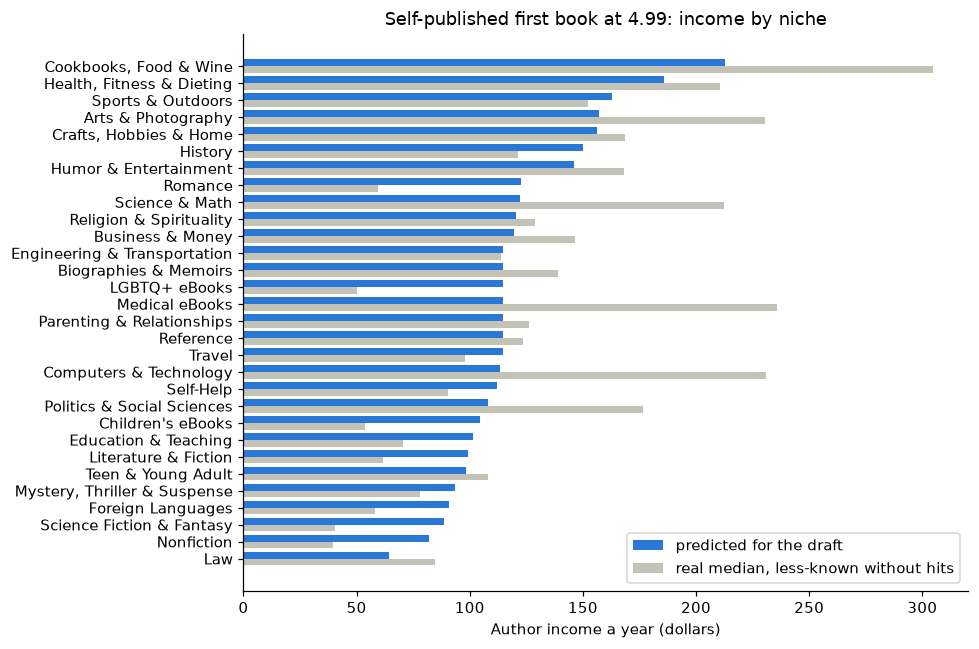

Spearman correlation, predicted vs real median: 0.67


,copies a year,income a year,real median income,real mean income,books
niche,,,,,
"Cookbooks, Food & Wine",66.0,213.0,305.0,1809.0,488
"Health, Fitness & Dieting",58.0,186.0,210.0,1284.0,613
Sports & Outdoors,50.0,163.0,152.0,903.0,420
Arts & Photography,49.0,157.0,231.0,1233.0,593
"Crafts, Hobbies & Home",48.0,156.0,169.0,866.0,234
History,46.0,150.0,122.0,766.0,1137
Humor & Entertainment,45.0,146.0,168.0,1218.0,351
Romance,38.0,122.0,60.0,527.0,1122
Science & Math,38.0,122.0,212.0,995.0,408


In [11]:
less_known = books[books["less_known"] & ~books["hit"]]
niches = sorted(books["niche"].unique())
niche_plan = pd.concat([plan_income({**draft, "niche": niche}, [4.99], routes=("self-published",)).assign(niche=niche) for niche in niches])
niche_plan = niche_plan.set_index("niche")[["copies a year", "income a year"]]
niche_plan["real median income"] = less_known.groupby("niche")["author_income"].median()
niche_plan["real mean income"] = less_known.groupby("niche")["author_income"].mean()
niche_plan["books"] = less_known.groupby("niche").size()
niche_plan = niche_plan.sort_values("income a year", ascending=False)

fig, ax = plt.subplots(figsize=(9, 6))
positions = np.arange(len(niche_plan))
ax.barh(positions - 0.2, niche_plan["income a year"], 0.4, color=BLUE, label="predicted for the draft")
ax.barh(positions + 0.2, niche_plan["real median income"], 0.4, color=GREY, label="real median, less-known without hits")
ax.set_yticks(positions, niche_plan.index)
ax.invert_yaxis()
ax.set_xlabel("Author income a year (dollars)")
ax.set_title("Self-published first book at 4.99: income by niche")
ax.legend()
plt.tight_layout()
plt.show()
print(f"Spearman correlation, predicted vs real median: {niche_plan['income a year'].corr(niche_plan['real median income'], method='spearman'):.2f}")
niche_plan.round(0)

- For a self-published first book at 4.99 dollars, the model predicts the most income in **Cookbooks, Food & Wine** (**213 dollars a year**), **Health, Fitness & Dieting** (186),
  **Sports & Outdoors** (163), **Arts & Photography** (157) and **Crafts, Hobbies & Home** (156).
- The lowest are **Law** (64), **Nonfiction** (82), **Science Fiction & Fantasy** (89), **Foreign Languages** (91) and **Mystery** (93). **Romance** is in the middle (122).
- The order agrees with the real medians of less-known authors without hits (Spearman **0.67**); Cookbooks lead in both (real median **305**). The model is too high for Romance
  (122 vs 60) and too low for Computers & Technology (113 vs 231).
- This confirms the EDA finding: **practical non-fiction** pays a new author more steadily than popular fiction niches.

Finally, the best price for this less-known author in the top predicted niche and in Romance, self-published.

In [12]:
top_niche = niche_plan.index[0]
price_check = pd.concat([plan_income({**draft, "niche": niche}, PRICES, routes=("self-published",)).assign(niche=niche)
                         for niche in [top_niche, "Romance"]])
price_check.pivot(index="price", columns="niche", values="income a year").round(0)

niche,"Cookbooks, Food & Wine",Romance
price,,
0.99,19.0,12.0
2.99,92.0,54.0
3.99,145.0,85.0
4.99,213.0,122.0
6.99,472.0,213.0
9.99,684.0,289.0
12.99,896.0,547.0
14.99,715.0,384.0


- For a self-published first book the predicted income is highest at **12.99 dollars**: **896 dollars a year** for a cookbook and **547** for Romance. Above 12.99 it falls (715
  and 384), because the royalty falls to 35%.
- Again, the price effect on copies is an association; the safe advice from the rules is **not to go below 2.99 or just above 12.99 dollars**, where the author keeps only 35%.

## 11. Limitations & ethics

**Limitations**

- **The sales are synthetic.** Copies sold were made from the number of ratings (`03`), so the model learns mostly what goes with ratings. With real sales
  data the numbers would change; the method would stay the same.
- **Price is not a cause here.** In this data more expensive books are often publisher books and books by known authors, so the model links a higher price
  with more copies. In a real shop a higher price usually means fewer copies. The model shows associations, not what happens if an author changes the price.
- **Hits cannot be predicted.** Nothing in the draft tells which book will sell tens of thousands of copies.
- `route` and `author_earlier_books` come from my rules and count only books in this catalog. Some "authors" are really companies.
- Marketing, cover, writing quality and reviews are not in the data. The books are from 2019–2021.

**Ethics**

- The model favours experienced authors and publishers. It should not decide which authors or books deserve support.
- A low prediction does not mean that a book is bad. It is meant as **rough information for an author**, not a promise of income.

## 12. Conclusion

**What we predicted.** The number of **copies a new Kindle book sells a year**, only from what an author knows before publishing: niche,
price, pages, series, publishing route (self-published, small or large publisher) and the author's earlier books. From the predicted copies and the 2026
Kindle rules I calculated the **author's income a year**.

**Answer to the main question.** *How many copies a year can a new Kindle book expect, from its niche, price, length, series, publishing route and the
author's experience?* **Partly.** Gradient boosting explains about **30%** of the differences in sales (R² 0.295), better than the baseline, and is within
2 times of the real copies for about one book in three (31.4%). It predicts the **typical** sales of a group well: a self-published first Romance book at
4.99 dollars sells about **38 copies** and earns the author about **122 dollars a year**. It cannot predict the sales of one particular book exactly, and it
cannot recognise hits. The **author's experience** and the **publishing route** matter most; the draft alone explains 17%.

**Sub-question.** For less-known authors without hits the model works as well as for others (R² 0.22). It puts **Cookbooks, Health, Sports, Arts and Crafts**
first and Romance and Mystery lower, as the EDA showed.

**For a future author.** One book rarely gives a large income. Self-publishing keeps the largest share of each sale between 2.99 and 12.99 dollars, and
experience with a series multiplies sales.

**Caution.** The sales are synthetic, so these numbers show how the method would work with real sales data, not real Amazon income.